# Step 2 · City list

**Goal:** create `data/cities.csv`, about 140 cities spread over the whole world, each one with
a download **priority**.

Constraint (from step 1): each city costs ~673 calls, so **about 14 cities fit in a day**. That
is why the size of each priority is a multiple of 14:

| Priority | Cities | Download days | What it adds |
|---|---|---|---|
| 1 | 28 | 2 | world coverage with large cities |
| 2 | 56 | 4 | fills the gaps |
| 3 | 56 | 4 | more detail |

**Source:** [Natural Earth](https://www.naturalearthdata.com/) v5.1.2, **public domain**.

The functions are in `pipelines.cities`; this notebook explains and runs them:
1. Download the source files (populated places, countries, coastline).
2. Build the candidates.
3. Distance to the coast.
4. One city per ERA5 cell.
5. Farthest-point selection and priorities.
6. Check the result (tables and map).
7. Save the CSV.

`data/cities.csv` is the only data file that goes to git.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pipelines.cities import (
    Coastline,
    build_candidates,
    distance_to_coast_km,
    download_source,
    haversine_km,
    latitude_band,
    nearest_segment,
    project_local_km,
    read_properties,
    select_cities,
)

# Project root: Jupyter starts in the notebook folder (notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SOURCES_FOLDER = ROOT / "data" / "sources"
CITIES_CSV = ROOT / "data" / "cities.csv"

# Selection parameters
MIN_POPULATION = 100_000  # candidates: cities with at least this population...
MIN_POPULATION_CAPITAL = 0  # ...or country capitals with at least this one
MIN_POPULATION_PRIORITY_1 = 1_000_000
CITIES_PER_PRIORITY = {1: 28, 2: 56, 3: 56}
COASTAL_KM = 50  # up to this distance, a city counts as coastal

# Manual adjustments, by id (e.g. "madrid-es").
# FORCE: id -> priority it goes into. Each forced city takes one place of that priority.
FORCE = {
    "phoenix-us": 1,
    "canberra-au": 2,
    "madrid-es": 2,
    "tokyo-jp": 2,
    "new-york-us": 2,
}
# EXCLUDE: ids never chosen (Mesa is part of the Phoenix metropolitan area)
EXCLUDE = ["mesa-us"]

## 1. Download the source files

Three GeoJSON files (JSON with geometries) from Natural Earth, saved in `data/sources/`
(ignored by git). If they already exist they are not downloaded again.
- `ne_10m_populated_places`: ~7,300 populated places, with country, coordinates and population (~19 MB).
- `ne_50m_admin_0_countries`: countries, for the country name and the **continent**.
- `ne_50m_coastline`: the coastline, to know whether a city is coastal.

In [2]:
places_path = download_source("ne_10m_populated_places", SOURCES_FOLDER)
countries_path = download_source("ne_50m_admin_0_countries", SOURCES_FOLDER)
coast_path = download_source("ne_50m_coastline", SOURCES_FOLDER)

places = read_properties(places_path)
countries = read_properties(countries_path)
print(f"Places: {len(places):,} · countries: {len(countries)}")

Places: 7,342 · countries: 242


## 2. Candidates

`build_candidates`:
- joins each place with its country by the 3-letter code `ADM0_A3` (South Sudan is `SSD` in one
  file and `SDS` in the other, so it is translated first; places with no country are dropped);
- keeps **country capitals** and **cities with at least 100,000 people** (`POP_MAX`, the urban
  area), and drops scientific stations, weather stations, historic places and Antarctica;
- creates a stable **`id`** like `madrid-es`: name without accents + country code. If two cities
  of the same country have the same name, the smaller one gets `-2`, `-3`...;
- adds the **latitude band** and the **ERA5 cell**.

**Latitude bands** (absolute latitude, with a `_north`/`_south` suffix; the lower limit is included):

| Band | Latitude | Note |
|---|---|---|
| tropical | < 23.44° | between the tropics of Cancer and Capricorn |
| subtropical | 23.44° – 35° | |
| temperate | 35° – 60° | Glasgow (55.9° N) and Moscow (55.8° N) are here |
| subpolar | 60° – 66.56° | |
| polar | ≥ 66.56° | inside the polar circles |

**ERA5 cell:** ERA5 is a 0.25° grid. Rounding latitude and longitude to the nearest multiple of
0.25 gives the cell (Madrid in step 1: 40.4168 → 40.5).

In [3]:
candidates = build_candidates(
    places, countries, MIN_POPULATION, MIN_POPULATION_CAPITAL, exclude=EXCLUDE
)
print(
    f"Candidates: {len(candidates):,} ({candidates['is_capital'].sum()} of them capitals)"
)

for name, latitude in [("Glasgow", 55.86), ("Moscow", 55.75)]:
    print(f"{name}: {latitude}° → {latitude_band(latitude)}")
candidates["continent"].value_counts()

Candidates: 3,113 (202 of them capitals)
Glasgow: 55.86° → temperate_north
Moscow: 55.75° → temperate_north


continent
Asia               1236
Europe              609
North America       462
Africa              447
South America       317
Oceania              38
Oceanic islands       4
Name: count, dtype: int64

## 3. Distance to the coast

The Natural Earth coastline (50m scale) is a list of **vertices** joined by straight
**segments**. On straight coasts the vertices can be more than 100 km apart, so measuring only
to the vertices can be very wrong:

```
   vertex A ●━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━● vertex B     ← coast
                                ┆
                                ┆ ~1 km  (distance to segment A–B)
                                ★ Mogadishu
   distance to A or B: ~57 km
```

`distance_to_coast_km` works in two steps:
1. **Haversine to every vertex.** The **haversine formula** gives the real distance in km
   between two points of the sphere. Exact, but it only looks at the vertices.
2. **Below 200 km, distance to the segments.** The area around the city is projected on a plane
   (*local equirectangular* projection: `x = R·Δlongitude·cos(latitude)`, `y = R·Δlatitude`),
   very accurate a few hundred km from the centre, where the distance from a point to a segment
   is simple geometry. The smaller of the two values is kept.

In [4]:
coast = Coastline.from_geojson(coast_path)
print(
    f"Coast vertices: {len(coast.lat):,} · segments: {len(coast.segment_start):,} "
    f"· longest segment: {coast.max_segment_km:.0f} km"
)

to_vertices_km, distance_km = distance_to_coast_km(
    coast, candidates["latitude"].to_numpy(), candidates["longitude"].to_numpy()
)
candidates["coast_distance_km"] = distance_km.round(0)
candidates["coastal"] = (candidates["coast_distance_km"] <= COASTAL_KM).astype(int)

fixed = ((to_vertices_km > COASTAL_KM) & (distance_km <= COASTAL_KM)).sum()
print(f"Coastal candidates: {candidates['coastal'].mean():.0%}")
print(f"Candidates that are only coastal when measuring to the segments: {fixed}")

Coast vertices: 60,416 · segments: 58,987 · longest segment: 137 km


Coastal candidates: 36%
Candidates that are only coastal when measuring to the segments: 8


### Drawing: vertices versus segments in Mogadishu

About 150 km around the city, in the local projection (the city at the centre). The dashed line
goes to the nearest vertex; the solid one, to the nearest point of a segment.

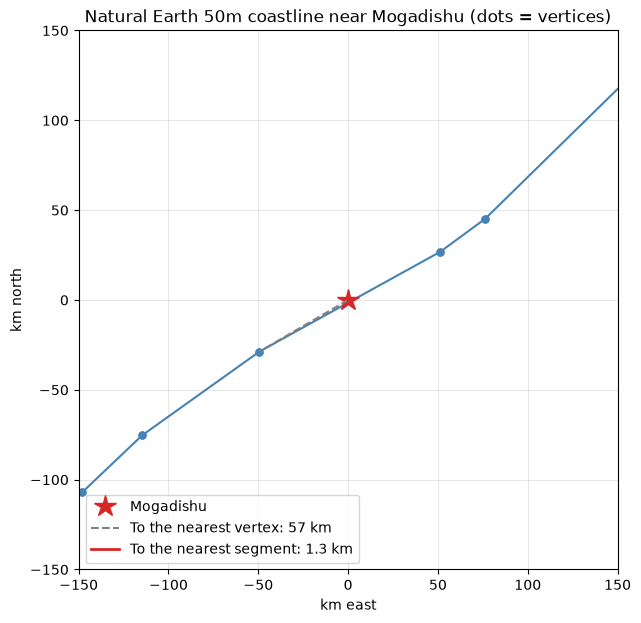

In [5]:
mogadishu = places[(places["NAME"] == "Mogadishu") & (places["ADM0_A3"] == "SOM")].iloc[
    0
]
lat0, lon0 = mogadishu["LATITUDE"], mogadishu["LONGITUDE"]

d_vertices = haversine_km(lat0, lon0, coast.lat, coast.lon)
i_vertex = np.argmin(d_vertices)
vx, vy = project_local_km(coast.lat[i_vertex], coast.lon[i_vertex], lat0, lon0)
near = np.flatnonzero(
    np.minimum(d_vertices[coast.segment_start], d_vertices[coast.segment_end]) < 400
)
d_segment, sx, sy = nearest_segment(coast, lat0, lon0, near)

fig, ax = plt.subplots(figsize=(7, 7))
for i in near:
    ends = [coast.segment_start[i], coast.segment_end[i]]
    xs, ys = project_local_km(coast.lat[ends], coast.lon[ends], lat0, lon0)
    ax.plot(xs, ys, "o-", color="steelblue", linewidth=1.5, markersize=5)
ax.plot(0, 0, "*", color="tab:red", markersize=16, label="Mogadishu")
ax.plot(
    [0, vx],
    [0, vy],
    "--",
    color="gray",
    label=f"To the nearest vertex: {d_vertices[i_vertex]:.0f} km",
)
ax.plot(
    [0, sx],
    [0, sy],
    "-",
    color="tab:red",
    linewidth=2,
    label=f"To the nearest segment: {d_segment:.1f} km",
)
ax.set_xlim(-150, 150)
ax.set_ylim(-150, 150)
ax.set_aspect("equal")
ax.set_xlabel("km east")
ax.set_ylabel("km north")
ax.set_title("Natural Earth 50m coastline near Mogadishu (dots = vertices)")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.show()

### Check with well-known coastal cities

All of them are on the coast, so all must come out coastal. They are looked up by country too
(`ADM0_A3`), because names repeat (for example, Barcelona in Venezuela).

In [6]:
KNOWN_COASTAL = [
    ("Mogadishu", "SOM"),
    ("Chennai", "IND"),
    ("Luanda", "AGO"),
    ("Karachi", "PAK"),
    ("Barcelona", "ESP"),
]

rows = []
for name, country_code in KNOWN_COASTAL:
    place = places[(places["NAME"] == name) & (places["ADM0_A3"] == country_code)].iloc[
        0
    ]
    vertices, final = distance_to_coast_km(
        coast, [place["LATITUDE"]], [place["LONGITUDE"]]
    )
    rows.append(
        {
            "city": name,
            "to vertices (km)": round(vertices[0], 1),
            "to segments (km)": round(final[0], 1),
        }
    )

known = pd.DataFrame(rows)
assert (known["to segments (km)"] <= COASTAL_KM).all(), "A coastal city is not coastal"
known

,city,to vertices (km),to segments (km)
0,Mogadishu,57.2,1.3
1,Chennai,30.8,2.0
2,Luanda,16.9,1.3
3,Karachi,14.4,6.6
4,Barcelona,7.8,2.4


## 4. One city per ERA5 cell

If two candidates fall in the same cell (for example, a city and a town next to it), the API
would return **the same data** for both. The most populated one is kept: the candidates are
already sorted by population, so it is the first one of each cell.

In [7]:
before = len(candidates)
candidates = candidates.drop_duplicates(subset=["cell_lat", "cell_lon"]).reset_index(
    drop=True
)
print(f"Candidates: {before:,} → {len(candidates):,} after keeping one per cell")

Candidates: 3,113 → 3,022 after keeping one per cell


## 5. Farthest-point selection

We want cities **spread over the whole world**, not piled up in Europe, India or China (where
there are more large cities). `farthest_point_selection`:

1. starts with the most populated city;
2. at each step adds the candidate **farthest from all the cities already chosen**;
3. repeats until it has as many as we want.

Each new city covers the biggest "gap" left on the map. It is **deterministic** (always the
same result), so no random numbers are needed. `distance_when_chosen_km` is how far the city was
from the rest when it was chosen; it goes down as the map fills up.

**Priorities** (`select_cities`):
- **Priority 1:** only among cities with at least one million people → 28 well-known cities
  that cover the world.
- **Priorities 2 and 3:** the same method goes on with all the candidates, starting from the
  cities already chosen.

**Manual adjustments:**
- `FORCE` maps `id → priority`. Each forced city goes first in its priority and **takes one of
  its places**; the automatic selection fills the rest, so the total is still 28 + 56 + 56. The
  selection is chained (each city conditions the next ones), so forcing a city changes the
  rest of the list from that priority on.
- `EXCLUDE` removes cities before starting.

In [8]:
missing = set(FORCE) - set(candidates["id"])
assert not missing, f"FORCE ids that are not candidates: {missing}"

chosen = select_cities(
    candidates,
    CITIES_PER_PRIORITY,
    force=FORCE,
    min_population_priority_1=MIN_POPULATION_PRIORITY_1,
)
counts = chosen["priority"].value_counts().sort_index().to_dict()
print("Cities per priority:", counts)

assert counts == CITIES_PER_PRIORITY and chosen["id"].is_unique
for city, priority in FORCE.items():
    assert chosen.loc[chosen["id"] == city, "priority"].item() == priority
assert not chosen["id"].isin(EXCLUDE).any()
print("OK: 28 + 56 + 56, forced cities in their priority, excluded ones out.")

chosen.loc[
    chosen["priority"] == 1,
    ["order", "name", "country", "continent", "population", "distance_when_chosen_km"],
]

Cities per priority: {1: 28, 2: 56, 3: 56}
OK: 28 + 56 + 56, forced cities in their priority, excluded ones out.


,order,name,country,continent,population,distance_when_chosen_km
0,1,Phoenix,United States of America,North America,3551000,NaN
1,2,Antananarivo,Madagascar,Africa,1697000,17418.0
2,3,Auckland,New Zealand,Oceania,1377200,10891.0
3,4,Jinxi,China,Asia,2426000,10045.0
4,5,Montevideo,Uruguay,South America,1513000,9576.0
5,6,Lisbon,Portugal,Europe,2812000,8706.0
6,7,Cilacap,Indonesia,Asia,1174964,5524.0
7,8,Isfahan,Iran,Asia,1628000,5434.0
8,9,Caracas,Venezuela,South America,2985000,5169.0
9,10,Yaoundé,Cameroon,Africa,1611000,4403.0


## 6. Check the result

What we look for:
- **every continent** in priority 1;
- **every latitude band**, with coastal and inland cities;
- **no repeated cell**, and a minimum distance between cities well above 25 km.

In [9]:
pd.crosstab(chosen["continent"], chosen["priority"], margins=True, margins_name="total")

priority,1,2,3,total
continent,,,,
Africa,7,8,13,28
Asia,7,13,17,37
Europe,3,9,9,21
North America,4,9,6,19
Oceania,3,9,6,18
Oceanic islands,0,1,1,2
South America,4,7,4,15
total,28,56,56,140


In [10]:
BAND_ORDER = [
    f"{band}_{half}"
    for half in ("north", "south")
    for band in ("polar", "subpolar", "temperate", "subtropical", "tropical")
]
table = pd.crosstab(
    chosen["latitude_band"],
    chosen["coastal"].map({1: "coastal", 0: "inland"}),
    margins=True,
    margins_name="total",
)
table.reindex([band for band in BAND_ORDER if band in table.index] + ["total"])

coastal,coastal,inland,total
latitude_band,,,
polar_north,1,1,2
subpolar_north,3,2,5
temperate_north,15,18,33
subtropical_north,6,13,19
tropical_north,25,14,39
temperate_south,3,2,5
subtropical_south,7,2,9
tropical_south,20,8,28
total,80,60,140


In [11]:
print(
    f"Coastal: {chosen['coastal'].mean():.0%} of the chosen cities "
    f"vs {candidates['coastal'].mean():.0%} of the candidates"
)
print(f"Capitals: {chosen['is_capital'].sum()} of {len(chosen)}")

repeated_cells = chosen.duplicated(subset=["cell_lat", "cell_lon"]).sum()
print(f"Repeated ERA5 cells: {repeated_cells}")
assert repeated_cells == 0

lat, lon = chosen["latitude"].to_numpy(), chosen["longitude"].to_numpy()
distances = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
np.fill_diagonal(distances, np.inf)
i, j = np.unravel_index(np.argmin(distances), distances.shape)
print(
    f"Closest pair: {chosen.loc[i, 'name']} – {chosen.loc[j, 'name']} ({distances[i, j]:.0f} km)"
)

Coastal: 57% of the chosen cities vs 36% of the candidates
Capitals: 34 of 140
Repeated ERA5 cells: 0
Closest pair: Boston – New York (299 km)


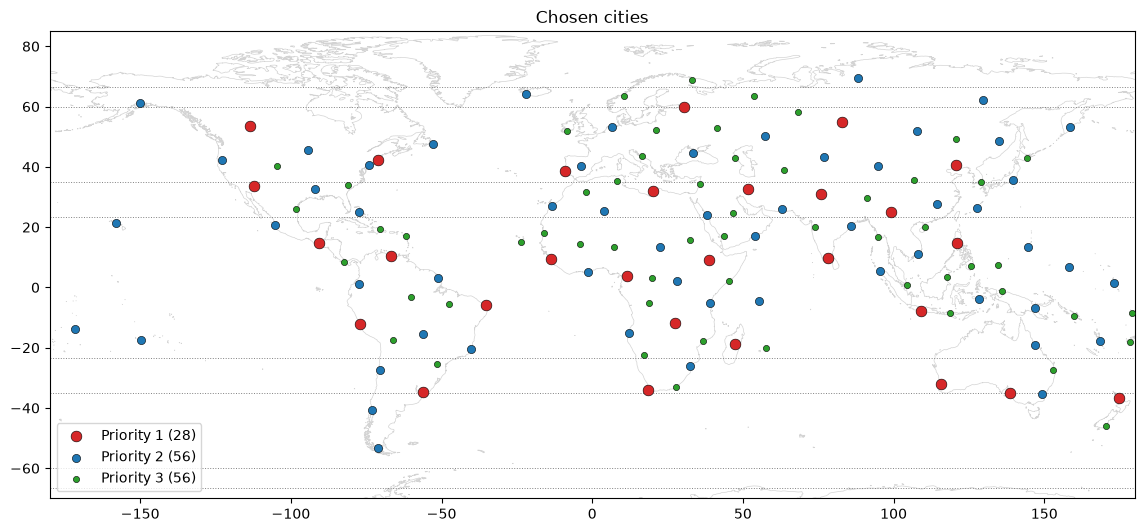

In [12]:
fig, ax = plt.subplots(figsize=(14, 7))
for line in coast.lines():
    ax.plot(line[:, 0], line[:, 1], color="lightgray", linewidth=0.5)

styles = {1: ("tab:red", 60), 2: ("tab:blue", 35), 3: ("tab:green", 20)}
for priority, (color, size) in styles.items():
    group = chosen[chosen["priority"] == priority]
    ax.scatter(
        group["longitude"],
        group["latitude"],
        s=size,
        color=color,
        edgecolor="black",
        linewidth=0.4,
        label=f"Priority {priority} ({len(group)})",
        zorder=3,
    )
for latitude in (-66.56, -60, -35, -23.44, 23.44, 35, 60, 66.56):  # band limits
    ax.axhline(latitude, color="gray", linestyle=":", linewidth=0.7)
ax.set_xlim(-180, 180)
ax.set_ylim(-70, 85)
ax.set_aspect("equal")
ax.set_title("Chosen cities")
ax.legend(loc="lower left")
plt.show()

## 7. Save the CSV

Final columns, in download order (`order`). The CSV goes to git: if the selection changes later,
the diff shows exactly which cities come in or go out.

In [13]:
CSV_COLUMNS = [
    "id",
    "name",
    "country",
    "country_code",
    "continent",
    "latitude",
    "longitude",
    "cell_lat",
    "cell_lon",
    "population",
    "is_capital",
    "latitude_band",
    "coast_distance_km",
    "coastal",
    "priority",
    "order",
]
cities = chosen[CSV_COLUMNS].copy()
cities["latitude"] = cities["latitude"].round(4)
cities["longitude"] = cities["longitude"].round(4)
cities["population"] = cities["population"].astype(int)
cities["coast_distance_km"] = cities["coast_distance_km"].astype(int)

CITIES_CSV.parent.mkdir(parents=True, exist_ok=True)
cities.to_csv(CITIES_CSV, index=False, encoding="utf-8")
print(f"Saved: {CITIES_CSV} ({len(cities)} cities)")
pd.read_csv(CITIES_CSV).head(10)

Saved: /home/administrator/climate-analytics/data/cities.csv (140 cities)


,id,name,country,country_code,continent,latitude,longitude,cell_lat,cell_lon,population,is_capital,latitude_band,coast_distance_km,coastal,priority,order
0,phoenix-us,Phoenix,United States of America,US,North America,33.5419,-112.0719,33.50,-112.00,3551000,0,subtropical_north,271,0,1,1
1,antananarivo-mg,Antananarivo,Madagascar,MG,Africa,-18.9147,47.5147,-19.00,47.50,1697000,1,tropical_south,162,0,1,2
2,auckland-nz,Auckland,New Zealand,NZ,Oceania,-36.8481,174.7630,-36.75,174.75,1377200,0,temperate_south,0,1,1,3
3,jinxi-cn,Jinxi,China,CN,Asia,40.7523,120.8280,40.75,120.75,2426000,0,temperate_north,11,1,1,4
4,montevideo-uy,Montevideo,Uruguay,UY,South America,-34.8561,-56.1730,-34.75,-56.25,1513000,1,subtropical_south,6,1,1,5
5,lisbon-pt,Lisbon,Portugal,PT,Europe,38.7247,-9.1468,38.75,-9.25,2812000,1,temperate_north,2,1,1,6
6,cilacap-id,Cilacap,Indonesia,ID,Asia,-7.7188,109.0154,-7.75,109.00,1174964,0,tropical_south,2,1,1,7
7,isfahan-ir,Isfahan,Iran,IR,Asia,32.7020,51.6981,32.75,51.75,1628000,0,subtropical_north,318,0,1,8
8,caracas-ve,Caracas,Venezuela,VE,South America,10.5029,-66.9190,10.50,-67.00,2985000,1,tropical_north,12,1,1,9
9,yaounde-cm,Yaoundé,Cameroon,CM,Africa,3.8686,11.5147,3.75,11.50,1611000,1,tropical_north,191,0,1,10


## Conclusions

**Result:** `data/cities.csv` with **140 cities** (28 of priority 1, 56 of priority 2 and 56 of
priority 3), chosen among 3,113 Natural Earth candidates (3,022 after keeping one per ERA5 cell).
No ERA5 cell is repeated. The closest pair is Boston – New York (299 km), because New York is
forced; among the automatically chosen cities the minimum distance is much larger.

**Spread**
- **Every continent:** Asia 37, Africa 28, Europe 21, North America 19, Oceania 18, South
  America 15 and 2 oceanic islands. Priority 1 already covers the six continents, so after the
  first download day there are cities from all over the world.
- **Every latitude band** of both hemispheres, from Murmansk and Norilsk (polar) in the north to
  Punta Arenas (53° S) in the south. The southern hemisphere has 42 cities: there is less land
  and fewer cities south of the equator.
- **80 coastal and 60 inland** (57 % coastal, against 36 % of the candidates). The farthest-point
  selection pushes towards the edges of continents and islands, which are the points farthest
  from the rest.
- 34 country capitals.

**Distance to the coast:** measuring to the coastline **segments**, not only to its vertices,
fixes large errors: Mogadishu goes from 57.2 km to 1.3 km and Chennai from 30.8 km to 2.0 km.
Only 8 candidates change from inland to coastal, but without this fix obvious cities were wrong.

**Manual adjustments:** Phoenix is forced in priority 1 (instead of Mesa, part of its
metropolitan area, which is excluded) and Canberra in priority 2, for an inland temperate city
of the southern hemisphere. **Tokyo, New York and Madrid** are forced in priority 2 so the
results include well-known large cities. Forcing them in priority 1 would change 95 of the 140
cities, because the selection is chained.

**Things to keep in mind**
- **The selection does not pick the big metropolises.** It rewards separation, not fame: in
  areas with many candidates it picks the one farthest from the chosen cities, often a medium
  city (Lianshan, Cilacap, Baoshan, Madurai...). London, Paris, Beijing, Delhi or São Paulo are
  not in the list.
- **Small Pacific islands:** with `MIN_POPULATION_CAPITAL = 0` tiny capitals come in, such as
  Palikir (4,645 people), Funafuti, Melekeok, South Tarawa or Port Vila: 7 of the 140 have fewer
  than 100,000 people. They add tropical oceanic climate; raise `MIN_POPULATION_CAPITAL` or add
  them to `EXCLUDE` if they are not wanted.
- **Known source error:** in Natural Earth, **Vila Velha** (Brazil, 1.2 million people) has the
  coordinates 3.2° N, 51.2° W, in Amapá, about 2,500 km from the real city (next to Vitória,
  20.3° S). Its data are therefore those of a point in Amapá, not of Vila Velha.
- **Same list as clima-mundial:** the 140 ids, their order and their values are identical to
  the list of the original project, so its downloaded data can be imported in step 3.